# v5 hydrostatics — supplied loading

Static freshwater flotation of the November 5 STEP hull, using the component masses and all three CG coordinates from `component-masses.csv`. This notebook is independent of the propulsion solve. Run cells from top to bottom with Python 3.13; it loads NavalToolbox from the existing project-local hydrostatics environment.

**Loading scope:** use only the filled rows, as requested. Blank rows are intentionally excluded from this case. The three filled battery rows are counted separately, despite their repeated IDs. Review the loading cell before interpreting the results as a complete boat.

Axes follow the v4 convention: CAD X transverse, Y forward from the transom, Z above the aft keel. NavalToolbox uses X = CAD Y, Y = −CAD X, Z unchanged. Freshwater density is 998.2 kg/m³. The hull is capped at its 12-inch rim to represent a dry interior; no extra tube buoyancy is included. These inherited assumptions still need physical confirmation.


## 1. Environment and run controls

Use the existing Python 3.13 kernel or the interpreter in `hull/hydrostatics/.venv`. Set `ALLOW_BLANK_MASSES = False` if a future case must require every row to have a mass.


In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'prop_motor_battery/willmarley.ipynb').is_file())
V5 = ROOT / 'hull/hydrostatics/v5-2026-11-05'
os.environ.setdefault('MPLCONFIGDIR', str(V5 / '.mpl-cache'))
local_site = ROOT / f'hull/hydrostatics/.venv/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages'
if local_site.is_dir() and str(local_site) not in sys.path:
    sys.path.insert(0, str(local_site))
import csv
import hashlib
import json
import math
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # Render safely in notebooks and headless runs.
import matplotlib.pyplot as plt
import navaltoolbox as nt
from IPython.display import display

# Blank rows are intentionally excluded from the supplied-row loading.
# This scope was confirmed by the user. Set False to require a mass for every listed row before solving.
ALLOW_BLANK_MASSES = True
DENSITY_KG_M3 = 998.2  # Freshwater; retained from v4.
KG_PER_LB = .45359237
IN_TO_M = .0254
REBUILD_GEOMETRY = False  # Cached, checked v5 geometry is supplied.
# To rebuild: use an interpreter with cadquery-ocp-novtk 8.0.1.1.0 installed.
# Set HAV_CAD_PYTHON and, for a target install, HAV_CAD_PACKAGE_PATH.
print(f'Python {sys.version.split()[0]}; NavalToolbox {version("navaltoolbox")}')


Matplotlib is building the font cache; this may take a moment.


Python 3.13.16; NavalToolbox 0.9.3


## 2. Geometry preparation and checks

The checked-in v5 mesh was built from the reviewed exterior transom, sides, V-bottom and chines (STEP faces 1–7); face 0's outer rim wire supplies the artificial cap. Inner shell faces are excluded. A source hash protects this face selection against changes to the STEP.

Routine runs use the saved geometry and verify both the STEP and STL hashes. To regenerate, install `hull/hydrostatics/requirements-geometry.txt` in a CAD interpreter and enable `REBUILD_GEOMETRY`. Set `HAV_CAD_PYTHON` to that interpreter if different from the notebook kernel; `HAV_CAD_PACKAGE_PATH` optionally points to a target package installation. Geometry regeneration is separate because the existing NavalToolbox environment does not include Open CASCADE.


In [2]:
import subprocess

CAD_PROGRAM = "import collections\nimport hashlib\nimport json\nimport math\nimport struct\nimport sys\nfrom pathlib import Path\nimport OCP.OCP as oc\n\nroot = Path(sys.argv[1])\nsource = root / 'hull/geometry/v5-2026-11-05/hull.step'\noutput = root / 'hull/hydrostatics/v5-2026-11-05/geometry'\nexpected = 'c0c8787bbfcdf710b55f49427a14a8c2a297b81ad33194a5c7f1055304bccbdc'\nassert hashlib.sha256(source.read_bytes()).hexdigest() == expected, 'Review changed STEP before selecting faces.'\n\ndef explore(shape, kind):\n    it = oc.TopExp.TopExp_Explorer(shape, kind)\n    while it.More():\n        yield it.Current()\n        it.Next()\n\ndef bounds(shape):\n    box = oc.Bnd.Bnd_Box()\n    oc.BRepBndLib.BRepBndLib.AddOptimal_s(shape, box, False, False)\n    lo, hi = box.CornerMin(), box.CornerMax()\n    return [[lo.X(), lo.Y(), lo.Z()], [hi.X(), hi.Y(), hi.Z()]]\n\ndef naval(point):\n    return (point.Y()/1000, -point.X()/1000, point.Z()/1000)\n\nreader = oc.STEPControl.STEPControl_Reader()\nassert reader.ReadFile(str(source)) == oc.IFSelect.IFSelect_RetDone\nreader.TransferRoots()\nshape = reader.OneShape()\nassert oc.BRepCheck.BRepCheck_Analyzer(shape).IsValid()\nfaces = [oc.TopoDS.TopoDS.Face(f) for f in explore(shape, oc.TopAbs.TopAbs_FACE)]\nassert len(faces) == 17\naudit = []\nfor i, face in enumerate(faces):\n    p = oc.GProp.GProp_GProps()\n    oc.BRepGProp.BRepGProp.SurfaceProperties_s(face, p)\n    c = p.CentreOfMass()\n    audit.append(dict(index=i, surface=str(oc.BRepAdaptor.BRepAdaptor_Surface(face).GetType()),\n                      area_mm2=p.Mass(), centroid_mm=[c.X(), c.Y(), c.Z()], bounds_mm=bounds(face)))\n# Reviewed against the v5 face audit: face 0 is the horizontal open rim;\n# 1 is exterior transom, 2/3 exterior sides, 4/5 exterior bottom, 6/7 chines.\n# 8--16 are interior/inner lip surfaces and do not bound displaced water.\nassert all(abs(audit[0]['bounds_mm'][j][2] - 304.8) < 1e-5 for j in (0, 1))\nassert abs(audit[1]['centroid_mm'][1]) < 1e-5\nouter = oc.BRepTools.BRepTools.OuterWire_s(faces[0])\ncap = oc.BRepBuilderAPI.BRepBuilderAPI_MakeFace(outer, True).Face()\nsew = oc.BRepBuilderAPI.BRepBuilderAPI_Sewing(1e-5)\nfor f in [*faces[1:8], cap]:\n    sew.Add(f)\nsew.Perform()\nshells = list(explore(sew.SewedShape(), oc.TopAbs.TopAbs_SHELL))\nassert len(shells) == 1\nsolid = oc.BRepBuilderAPI.BRepBuilderAPI_MakeSolid(oc.TopoDS.TopoDS.Shell(shells[0])).Solid()\nassert oc.BRepLib.BRepLib.OrientClosedSolid_s(solid)\nassert oc.BRepCheck.BRepCheck_Analyzer(solid).IsValid()\np = oc.GProp.GProp_GProps()\noc.BRepGProp.BRepGProp.VolumeProperties_s(solid, p)\nexact_volume = p.Mass()/1e9\noc.BRepMesh.BRepMesh_IncrementalMesh(solid, .3, False, .15, True).Perform()\ntriangles = []\nseen = set()\nfor f in explore(solid, oc.TopAbs.TopAbs_FACE):\n    face = oc.TopoDS.TopoDS.Face(f)\n    loc = oc.TopLoc.TopLoc_Location()\n    mesh = oc.BRep.BRep_Tool.Triangulation_s(face, loc)\n    assert mesh is not None\n    for i in range(1, mesh.NbTriangles()+1):\n        triangle = mesh.Triangle(i)\n        ids = [triangle.Value(j) for j in (1, 2, 3)]\n        if face.Orientation() == oc.TopAbs.TopAbs_REVERSED:\n            ids.reverse()\n        tri = tuple(tuple(round(v, 8) for v in naval(mesh.Node(k).Transformed(loc.Transformation()))) for k in ids)\n        key = tuple(sorted(tri))\n        if len(set(tri)) == 3 and key not in seen:\n            seen.add(key)\n            triangles.append(tri)\nedges = collections.Counter()\ndirections = collections.Counter()\nvolume = 0.0\nfor a, b, c in triangles:\n    for u, v in [(a,b),(b,c),(c,a)]:\n        edge = tuple(sorted((u,v)))\n        edges[edge] += 1\n        directions[edge] += 1 if (u,v) == edge else -1\n    volume += (a[0]*(b[1]*c[2]-b[2]*c[1]) + a[1]*(b[2]*c[0]-b[0]*c[2]) + a[2]*(b[0]*c[1]-b[1]*c[0]))/6\nassert all(n == 2 for n in edges.values()), 'Mesh is not watertight.'\nassert all(n == 0 for n in directions.values()), 'Inconsistent triangle winding.'\nassert volume > 0\nerror = abs(volume/exact_volume-1)\nassert error < .001\nrim = []\nfor e in explore(outer, oc.TopAbs.TopAbs_EDGE):\n    curve = oc.BRepAdaptor.BRepAdaptor_Curve(oc.TopoDS.TopoDS.Edge(e))\n    for i in range(81):\n        t = curve.FirstParameter()+(curve.LastParameter()-curve.FirstParameter())*i/80\n        rim.append(naval(curve.Value(t)))\nassert all(abs(p[2]-.3048) < 1e-6 for p in rim)\nvertices = [p for tri in triangles for p in tri]\nmesh_bounds = [[min(p[j] for p in vertices) for j in range(3)], [max(p[j] for p in vertices) for j in range(3)]]\nassert math.isclose(mesh_bounds[1][0]-mesh_bounds[0][0],1.8288,abs_tol=1e-5)\nassert math.isclose(mesh_bounds[1][2]-mesh_bounds[0][2],.3048,abs_tol=1e-5)\noutput.mkdir(parents=True, exist_ok=True)\ntarget = output/'hull-envelope.stl'\nwith target.open('wb') as stream:\n    stream.write(b'v5 capped exterior; metres'.ljust(80,b'\\0'))\n    stream.write(struct.pack('<I',len(triangles)))\n    for tri in triangles:\n        stream.write(struct.pack('<12fH',0,0,0,*(v for p in tri for v in p),0))\nreport = dict(source=str(source.relative_to(root)),source_sha256=expected,\n              stl_sha256=hashlib.sha256(target.read_bytes()).hexdigest(),\n              axes='Naval X = CAD Y; naval Y = -CAD X; Z up; metres, full scale.',\n              exterior_face_indices=list(range(1,8)),cap='Outer wire of planar rim face 0, at CAD Z=12 inches',\n              face_audit=audit,watertight=True,winding_consistent=True,triangles=len(triangles),\n              bounds_m=mesh_bounds,exact_envelope_volume_m3=exact_volume,mesh_volume_m3=volume,\n              relative_volume_error=error,\n              assumption='Dry interior; artificial cap at 12-inch rim. No additional tube or appendage buoyancy. Invalid when rim immersed.')\n(output/'deck-edge.json').write_text(json.dumps(rim,indent=2)+'\\n')\n(output/'geometry-report.json').write_text(json.dumps(report,indent=2)+'\\n')\nprint(json.dumps({k:v for k,v in report.items() if k!='face_audit'},indent=2))\n"
if REBUILD_GEOMETRY:
    cad_env = os.environ.copy()
    if os.environ.get('HAV_CAD_PACKAGE_PATH'):
        cad_env['PYTHONPATH'] = os.environ['HAV_CAD_PACKAGE_PATH']
    cad = subprocess.run([os.environ.get('HAV_CAD_PYTHON', sys.executable), '-c', CAD_PROGRAM, str(ROOT)],
                         env=cad_env, capture_output=True, text=True)
    print(cad.stdout)
    if cad.returncode:
        raise RuntimeError(cad.stderr)
geometry_summary = json.loads((V5/'geometry/geometry-report.json').read_text())
assert geometry_summary['watertight'] and geometry_summary['winding_consistent']
assert geometry_summary['relative_volume_error'] < .001
display({k:v for k,v in geometry_summary.items() if k != 'face_audit'})


{'source': 'hull/geometry/v5-2026-11-05/hull.step',
 'source_sha256': 'c0c8787bbfcdf710b55f49427a14a8c2a297b81ad33194a5c7f1055304bccbdc',
 'stl_sha256': '437345007ec59899474e5a7d7472af1868bd7d12ec2563b4d2cd0c490591797a',
 'axes': 'Naval X = CAD Y; naval Y = -CAD X; Z up; metres, full scale.',
 'exterior_face_indices': [1, 2, 3, 4, 5, 6, 7],
 'cap': 'Outer wire of planar rim face 0, at CAD Z=12 inches',
 'watertight': True,
 'winding_consistent': True,
 'triangles': 13272,
 'bounds_m': [[0.0, -0.33326341, 0.0], [1.8288, 0.33326341, 0.3048]],
 'exact_envelope_volume_m3': 0.18730444425570958,
 'mesh_volume_m3': 0.1872867607860024,
 'relative_volume_error': 9.441030498469338e-05,
 'assumption': 'Dry interior; artificial cap at 12-inch rim. No additional tube or appendage buoyancy. Invalid when rim immersed.'}

## 3. Review included and excluded rows

Every filled row needs a positive mass and finite X/Y/Z CG values. Blank masses are listed explicitly. CSV line numbers distinguish repeated battery IDs without changing the user’s input file. Masses are pounds and CG coordinates are inches.


In [3]:
MASS_FILE = V5 / 'component-masses.csv'
input_digest = hashlib.sha256(MASS_FILE.read_bytes()).hexdigest()
with MASS_FILE.open(newline='') as stream:
    raw_rows = list(csv.DictReader(stream))
included, unresolved = [], []
seen_ids = {}
for line, raw in enumerate(raw_rows, 2):
    row = {k: (v or '').strip() for k, v in raw.items()}
    if not row['mass_lbs']:
        if any(row[k] for k in ['cg_x_in', 'cg_y_in', 'cg_z_in']):
            raise ValueError(f'Line {line}: CG provided without mass.')
        unresolved.append(dict(csv_line=line, **row))
        continue
    values = [float(row[k]) for k in ['mass_lbs', 'cg_x_in', 'cg_y_in', 'cg_z_in']]
    if not all(math.isfinite(x) for x in values) or values[0] <= 0:
        raise ValueError(f'Line {line}: mass must be positive; mass and CG must be finite.')
    identity = row['component_id']
    seen_ids[identity] = seen_ids.get(identity, 0) + 1
    included.append(dict(csv_line=line, component_id=identity,
                         label=f'{row["component"]} (CSV line {line})',
                         mass_lbs=values[0], cg_x_in=values[1], cg_y_in=values[2], cg_z_in=values[3],
                         source=row['source'], notes=row['notes']))
if not included:
    raise ValueError('No masses have been supplied.')
duplicate_ids = [k for k, n in seen_ids.items() if n > 1]
loading = pd.DataFrame(included)
total_lb = float(loading.mass_lbs.sum())
total_kg = total_lb * KG_PER_LB
cg_cad_in = np.average(loading[['cg_x_in', 'cg_y_in', 'cg_z_in']], axis=0, weights=loading.mass_lbs)
# Proper rotation; retain the actual transverse offset rather than forcing zero.
cg_naval_m = np.array([cg_cad_in[1], -cg_cad_in[0], cg_cad_in[2]]) * IN_TO_M
print(f'Total supplied mass: {total_lb:.3f} lb / {total_kg:.3f} kg')
print('Whole-boat CAD CG (X transverse, Y forward, Z up), inches:', cg_cad_in.round(5))
display(loading)
if duplicate_ids:
    print('Repeated component IDs retained as separate physical rows:', duplicate_ids)
    print('In particular, the three battery rows are all included; the CSV was not changed.')
if unresolved:
    print(f'SUPPLIED-ROW CASE: {len(unresolved)} blank rows intentionally excluded:')
    display(pd.DataFrame(unresolved)[['csv_line', 'component_id', 'component']])
    if not ALLOW_BLANK_MASSES:
        raise ValueError('Fill all masses or explicitly allow blank rows.')


Total supplied mass: 148.595 lb / 67.402 kg
Whole-boat CAD CG (X transverse, Y forward, Z up), inches: [-1.040000e-03  2.348884e+01  7.663020e+00]


,csv_line,component_id,label,mass_lbs,cg_x_in,cg_y_in,cg_z_in,source,notes
0,2,printed_shell,Printed hull shell (CSV line 2),20.000,0.000,28.210,4.195,cad,Include integral printed hardpoints
1,8,battery_1,Battery 1 (CSV line 8),30.865,0.000,28.133,5.401,cad,Duplicate row for additional batteries
2,9,battery_1,Battery 1 (CSV line 9),30.865,-0.005,28.139,9.401,cad,Duplicate row for additional batteries
3,10,battery_1,Battery 1 (CSV line 10),30.865,0.000,28.139,13.400,cad,Duplicate row for additional batteries
4,11,motor_port,Port motor assembly (CSV line 11),3.000,-5.100,18.883,3.692,cad,Include propeller strut and mounts unless list...
5,12,motor_starboard,Starboard motor assembly (CSV line 12),3.000,5.100,18.883,3.692,cad,Include propeller strut and mounts unless list...
6,21,payload_aft,Aft payload (CSV line 21),30.000,0.000,6.916,5.406,cad,Exclude equipment already listed


Repeated component IDs retained as separate physical rows: ['battery_1']
In particular, the three battery rows are all included; the CSV was not changed.
SUPPLIED-ROW CASE: 13 blank rows intentionally excluded:


,csv_line,component_id,component
0,3,glass_resin_finish,Fiberglass resin fairing and paint
1,4,tube_port,Port tube
2,5,tube_starboard,Starboard tube
3,6,backbone,Backbone and frame
4,7,baseboard,Baseboard
5,13,esc_port,Port motor controller
6,14,esc_starboard,Starboard motor controller
7,15,electronics_enclosure,Electronics enclosure
8,16,electronics,Electronics and power distribution
9,17,sensor_tower,Sensor tower and sensors


## 4. Solve, verify and save

First check NavalToolbox against a centered analytical box; then solve all included component masses on the v5 envelope. Preserve the small transverse CG offset from the input. Require buoyancy mass balance within 0.1% and check the native loading CG against the mass-weighted CSV CG.

Results are written to a new timestamped folder under `results/`, including the input snapshot, included and excluded components, geometry provenance, numerical checks, CSV, figure and report. Positive trim is bow down. Initial transverse GM describes small-angle roll stability only; rim immersion invalidates the dry-interior model. End drafts are waterplane references at the hull perpendiculars, not local water depth above the curved bottom.


,Baseline
mass_lb,148.595
mass_kg,67.401558
draft_aft_in,6.679198
draft_midship_in,6.019775
draft_forward_in,5.360353
trim_bow_down_deg,-1.049386
heel_deg,-0.008895
freeboard_min_in,5.317978
waterline_length_in,62.455529
submerged_length_in,62.455529


Analytical box maximum relative error: 6.103515624955591e-05
Mass balance error: 0.00124%


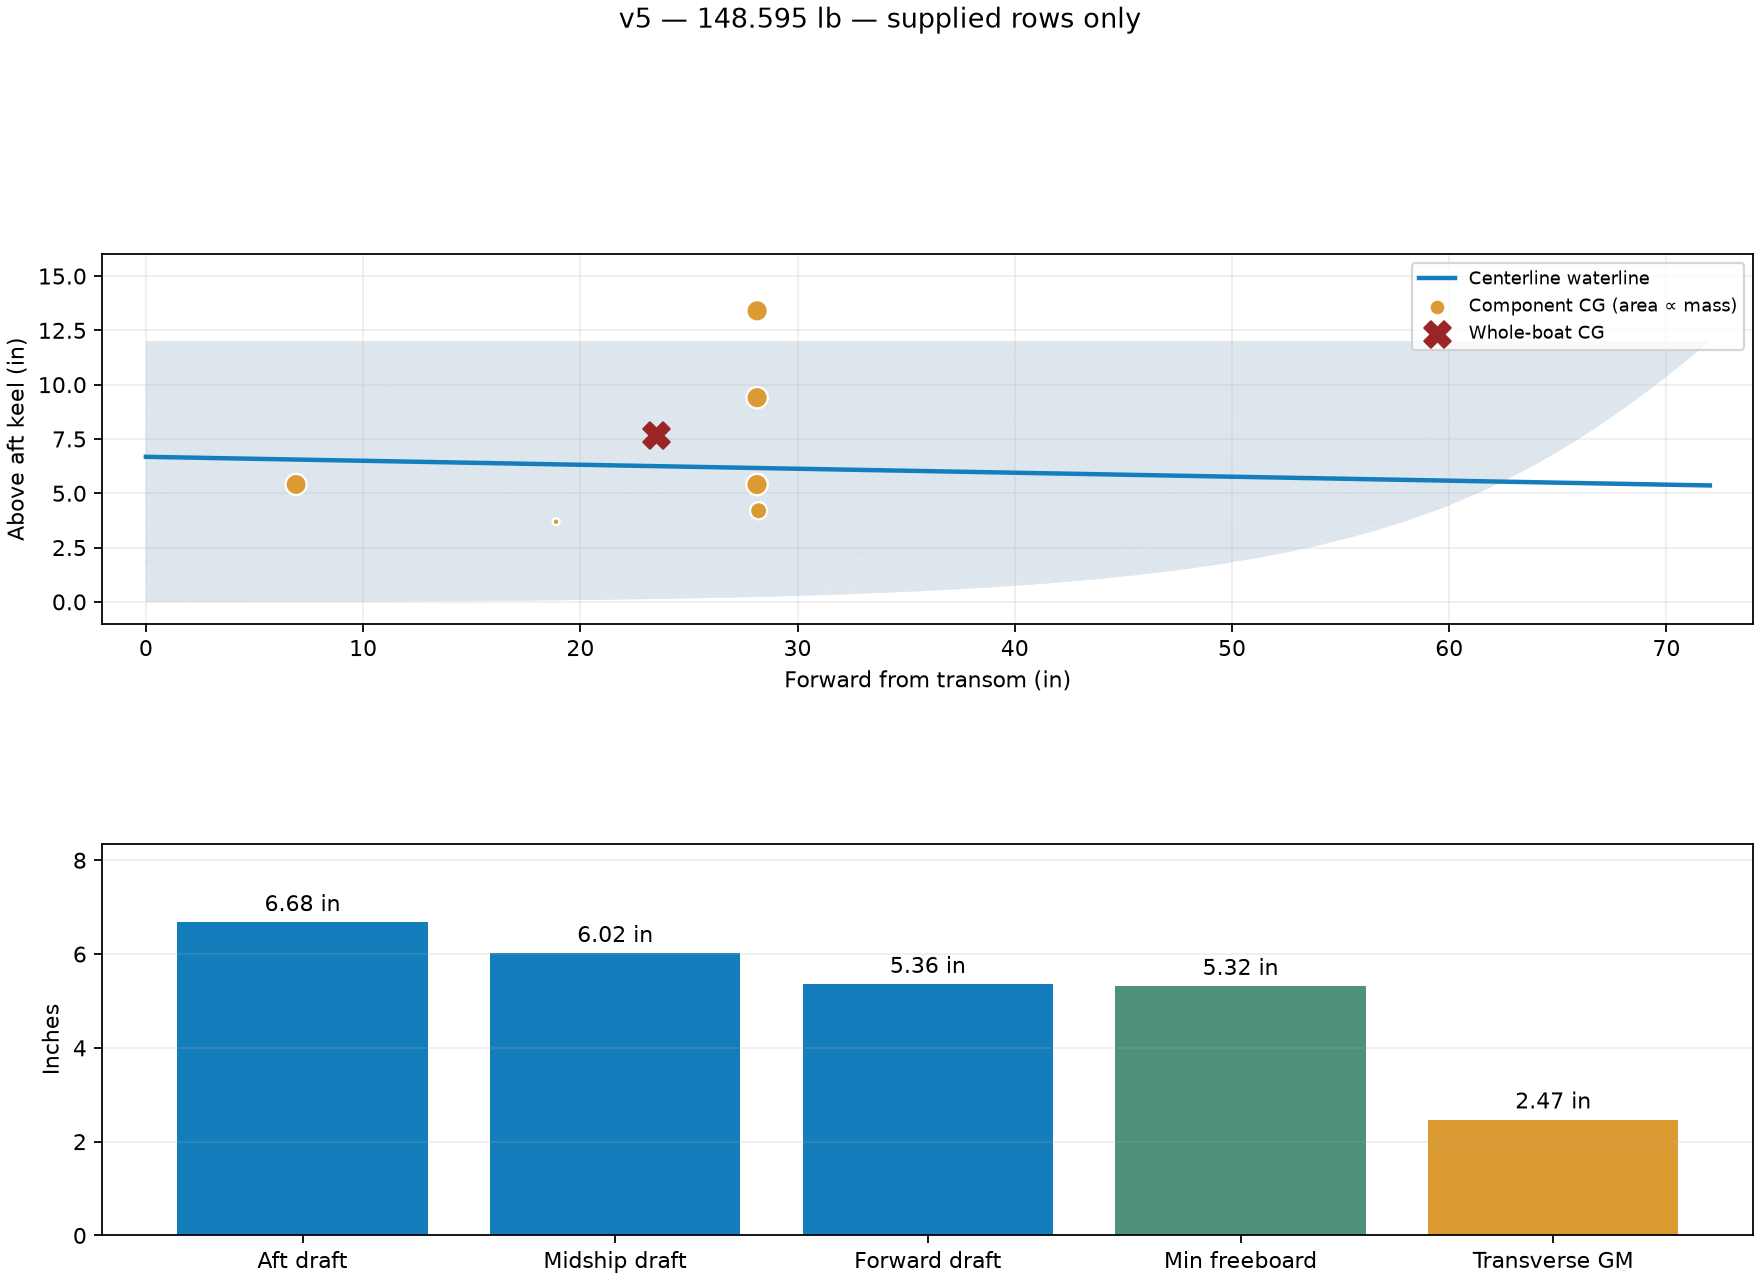

Saved results: hull/hydrostatics/v5-2026-11-05/results/navaltoolbox-20261105T220511194489Z


In [4]:
geometry_dir = V5 / 'geometry'
geometry = json.loads((geometry_dir / 'geometry-report.json').read_text())
mesh_file = geometry_dir / 'hull-envelope.stl'
assert hashlib.sha256(mesh_file.read_bytes()).hexdigest() == geometry['stl_sha256']
assert hashlib.sha256((ROOT / geometry['source']).read_bytes()).hexdigest() == geometry['source_sha256']
assert hashlib.sha256(MASS_FILE.read_bytes()).hexdigest() == input_digest, 'Loading changed: rerun input cell.'

def box_benchmark():
    length, beam, height, draft = 1.8288, .6096, .3048, .12
    box = nt.Vessel(nt.Hull.from_box(length, beam, height))
    xmin, xmax, ymin, ymax, zmin, zmax = box.get_bounds()
    mass = length * beam * draft * DENSITY_KG_M3
    load = nt.LoadingCondition('Analytical box')
    load.add_mass_simple('Centered box mass', mass,
                         ((xmin+xmax)/2, (ymin+ymax)/2, zmin+draft/2), nt.MassCategory.lightship())
    s = nt.HydrostaticsCalculator(box, water_density=DENSITY_KG_M3).from_loading(load)
    expected = dict(volume=length*beam*draft, waterplane_area=length*beam,
                    wetted_surface_area=length*beam+2*(length+beam)*draft)
    errors = {name: abs(float(getattr(s, name))/exact-1) for name, exact in expected.items()}
    assert max(errors.values()) < .005, errors
    assert abs(s.trim) < .05 and abs(s.heel) < .05
    return errors

benchmark = box_benchmark()
vessel = nt.Vessel(nt.Hull(str(mesh_file)))
rim = [tuple(point) for point in json.loads((geometry_dir / 'deck-edge.json').read_text())]
vessel.add_deck_edge(nt.DeckEdge.from_points('Complete v5 rim', rim, nt.DeckEdgeSide.port()))
condition = nt.LoadingCondition('v5 supplied-row loading' if unresolved else 'v5 complete loading')
for row in included:
    cog = (row['cg_y_in']*IN_TO_M, -row['cg_x_in']*IN_TO_M, row['cg_z_in']*IN_TO_M)
    condition.add_mass_simple(row['label'], row['mass_lbs']*KG_PER_LB, cog, nt.MassCategory.lightship())
calculator = nt.HydrostaticsCalculator(vessel, water_density=DENSITY_KG_M3)
state = calculator.from_loading(condition)
balance_error = abs(float(state.volume)*DENSITY_KG_M3/total_kg-1)
assert math.isfinite(balance_error) and balance_error < .001, 'Buoyancy balance failed.'
assert state.freeboard is not None
result = dict(mass_lb=total_lb, mass_kg=total_kg,
              draft_aft_in=float(state.draft_ap)/IN_TO_M,
              draft_midship_in=float(state.draft)/IN_TO_M,
              draft_forward_in=float(state.draft_fp)/IN_TO_M,
              trim_bow_down_deg=float(state.trim), heel_deg=float(state.heel),
              freeboard_min_in=float(state.freeboard)/IN_TO_M,
              waterline_length_in=float(state.lwl)/IN_TO_M,
              submerged_length_in=float(state.los)/IN_TO_M,
              wetted_area_in2=float(state.wetted_surface_area)/IN_TO_M**2,
              waterplane_area_in2=float(state.waterplane_area)/IN_TO_M**2,
              displacement_volume_l=float(state.volume)*1000,
              gm_transverse_in=None if state.gmt is None else float(state.gmt)/IN_TO_M,
              mass_balance_relative_error=balance_error,
              dry_hull_assumption_ok=bool(state.freeboard > 0))
assert all(v is None or math.isfinite(v) for v in result.values())
# Check that the native component loading actually preserved the supplied CG.
native_cg = np.array([state.lcg, state.tcg, state.vcg], dtype=float)
assert np.allclose(native_cg, cg_naval_m, atol=1e-7), (native_cg, cg_naval_m)
display(pd.DataFrame([result]).T.rename(columns={0:'Baseline'}))
print('Analytical box maximum relative error:', max(benchmark.values()))
print(f'Mass balance error: {balance_error:.5%}')
if not result['dry_hull_assumption_ok']:
    print('RIM IMMERSED: dry-interior flotation assumption is invalid.')
if result['gm_transverse_in'] is not None and result['gm_transverse_in'] <= 0:
    print('NONPOSITIVE TRANSVERSE GM: this equilibrium is not initially stable in roll.')

# Save an immutable run folder; rerunning never overwrites earlier results.
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
output = V5 / 'results' / f'navaltoolbox-{stamp}'
output.mkdir(parents=True, exist_ok=False)
pd.DataFrame([result]).to_csv(output / 'hydrostatics.csv', index=False)
pd.DataFrame(included).to_csv(output / 'included-components.csv', index=False)
pd.DataFrame(unresolved).to_csv(output / 'excluded-blank-components.csv', index=False)
(output / 'component-masses-input.csv').write_bytes(MASS_FILE.read_bytes())
assumptions = [
    'Freshwater density 998.2 kg/m³, retained from v4.',
    'CAD X transverse; CAD Y forward from transom; CAD Z above aft keel, as in v4. Physical transverse sign unconfirmed.',
    'Dry interior below the 12-inch rim; no added tube/appendage buoyancy. Rim immersion invalidates this envelope.',
    'Every filled CSV row is included independently, including all three repeated battery IDs.',
    'Blank component rows are intentionally excluded from this supplied-row loading, as requested.' if unresolved else 'All component rows have masses.',
    'Static equilibrium and initial GM only; no speed, planing, waves or large-angle stability calculation.'
]
metadata = dict(created_utc=datetime.now(timezone.utc).isoformat(),
                navaltoolbox_version=version('navaltoolbox'),
                input_file=str(MASS_FILE.relative_to(ROOT)), input_sha256=input_digest,
                density_kg_m3=DENSITY_KG_M3, cg_cad_in=cg_cad_in.tolist(), cg_naval_m=cg_naval_m.tolist(),
                loading_scope="Filled component rows only; blank masses excluded as requested", included_components=included, excluded_blank_components=unresolved,
                duplicate_ids=duplicate_ids, assumptions=assumptions, geometry=geometry,
                analytical_box_relative_errors=benchmark, result=result)
(output / 'study.json').write_text(json.dumps(metadata, indent=2, allow_nan=False)+'\n')

# Longitudinal section: hull silhouette, centerline waterline, component CGs.
from matplotlib.collections import PolyCollection
import struct
data = mesh_file.read_bytes()
count = struct.unpack_from('<I', data, 80)[0]
triangles = np.array([struct.unpack_from('<12fH',data,84+50*i)[3:12] for i in range(count)]).reshape(-1,3,3)
fig, axes = plt.subplots(2,1,figsize=(11,8),gridspec_kw={'height_ratios':[2,1]},layout='constrained')
ax = axes[0]
ax.add_collection(PolyCollection(triangles[:,:,[0,2]]/IN_TO_M,facecolors='#dce5ed',edgecolors='none',alpha=.8))
ax.plot([0,72],[result['draft_aft_in'],result['draft_forward_in']],color='#147dbc',lw=2,label='Centerline waterline')
sizes = loading.mass_lbs.to_numpy()*3
ax.scatter(loading.cg_y_in,loading.cg_z_in,s=sizes,facecolors='#db9b32',edgecolors='white',label='Component CG (area ∝ mass)',zorder=4)
ax.scatter(cg_cad_in[1],cg_cad_in[2],marker='X',s=140,color='#9b2525',label='Whole-boat CG',zorder=5)
ax.set(xlim=(-2,74),ylim=(-1,max(16,float(loading.cg_z_in.max())+2)),xlabel='Forward from transom (in)',ylabel='Above aft keel (in)')
ax.set_aspect('equal',adjustable='box')
ax.grid(alpha=.2)
ax.legend(loc='upper right',fontsize=8)
labels=['Aft draft','Midship draft','Forward draft','Min freeboard','Transverse GM']
values=[result[k] for k in ['draft_aft_in','draft_midship_in','draft_forward_in','freeboard_min_in','gm_transverse_in']]
axes[1].bar(labels,[v if v is not None else np.nan for v in values],color=['#147dbc']*3+['#4d9178','#db9b32'])
for i,value in enumerate(values):
    if value is not None:
        axes[1].annotate(f'{value:.2f} in',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
axes[1].set_ylabel('Inches')
axes[1].margins(y=.25)
axes[1].grid(axis='y',alpha=.2)
fig.suptitle(f'v5 — {total_lb:.3f} lb — '+('supplied rows only' if unresolved else 'supplied loading'))
fig.savefig(output/'hydrostatics.png',dpi=160)
from IPython.display import Image
display(Image(filename=str(output / "hydrostatics.png")))
plt.close(fig)
summary = '\n'.join(f'- {label}: {result[key]:.3f} {unit}' for label,key,unit in [
    ('Total mass','mass_lb','lb'),('Aft draft','draft_aft_in','in'),('Midship draft','draft_midship_in','in'),
    ('Forward draft','draft_forward_in','in'),('Trim (positive bow down)','trim_bow_down_deg','deg'),
    ('Heel','heel_deg','deg'),('Minimum rim freeboard','freeboard_min_in','in'),
    ('Waterline length','waterline_length_in','in'),('Wetted area','wetted_area_in2','in²')])
gm_text = 'unavailable' if result['gm_transverse_in'] is None else f"{result['gm_transverse_in']:.3f} in"
report = '# v5 NavalToolbox hydrostatics\n\n'
report += ('**Supplied-row loading — blank component weights intentionally excluded as requested.**\n\n' if unresolved else '')
report += summary + f'\n- Initial transverse GM: {gm_text}\n\n'
report += f'Whole-boat CAD CG (X/Y/Z): {cg_cad_in[0]:.5f}, {cg_cad_in[1]:.5f}, {cg_cad_in[2]:.5f} in.\n\n'
report += '![Hydrostatics profile and results](hydrostatics.png)\n\n'
report += '## Assumptions and loading scope\n\n' + '\n'.join('- '+s for s in assumptions)+'\n\n'
if unresolved:
    report += 'Intentionally excluded blank rows: ' + ', '.join(r['component'] for r in unresolved) + '.\n\n'
report += '## Numerical checks\n\n'
report += f"Mesh/STEP volume difference: {geometry['relative_volume_error']:.5%}. Mass-balance error: {balance_error:.5%}. Maximum analytical-box error: {max(benchmark.values()):.5%}. These checks establish numerical consistency, not physical validation.\n\n"
report += '[CSV results](hydrostatics.csv) · [Full inputs, assumptions and checks](study.json) · [Original loading snapshot](component-masses-input.csv)\n'
(output/'REPORT.md').write_text(report)
print('Saved results:', output.relative_to(ROOT))
